# Player Archetype Analysis; Feature Preprocessing (Transformation & Scaling) [Milestone 3.1]

**Project Objective**:
Gather football player and team performance data across Europe's top 5 leagues to create a scouting dashboard that leverages unsupervised Machine Learning to identify statistical profiles ("player archetypes") and uncover comparable or undervalued talents.

### Milestone 3.1 Objectives:
1. Separate descriptive columns (`player_identifier`, `Player`, `Nation`, `Age`, `Pos`, `Primary_Pos`, `Squad`, `Comp`, league playing percentages) from the numeric performance feature matrix.
2. Address heavy skewed and zero-inflated distributions via Yeo-Johnson power transformations and justified (via domain knowledge) custom weighting.
3. Standardise/scale features using `StandardScaler` and evaluate against `RobustScaler`.


## 1. Setup & Ingestion


In [4]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.preprocessing import PowerTransformer, RobustScaler, StandardScaler

# Add repo root to path if running notebook from notebooks/ directory
repo_root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(repo_root) not in sys.path:
    sys.path.append(str(repo_root))

from scripts.constants import PRIMARY_POS_ORDER
from scripts.featureset.columns import DESCRIPTIVE_COLS
from scripts.featureset.transform import (
    DEFAULT_RARE_EVENT_WEIGHTS,
    SkewStandardScalerPipeline,
    apply_feature_weights,
    detect_skewed_features,
    power_transform_features,
    scale_features,
    separate_features_and_metadata,
)

warnings.filterwarnings('ignore', category=UserWarning)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10


### Ingesting the Cleaned Featureset
Import `player_featureset.csv`, which has previously been processed by:
- Goalkeepers filtered out.
- Min 600 minutes played per club filter.
- Multi-club players aggregated.
- Metrics normalised to per-90 (with a `_p90` suffix).
- Redundant within-group features pruned.


In [9]:
featureset_path = repo_root / 'data' / 'processed' / 'player_featureset.csv'
df = pd.read_csv(featureset_path)

print(f"{df.shape[0]} players, {df.shape[1]} total columns")
print(f"Missing values: {df.isna().sum().sum()}")
df.sample(10)


1737 players, 125 total columns
Missing values: 0


,player_identifier,Player,Nation,Age,Pos,Primary_Pos,Num_Pos,Squad,Comp,passing_foot_pref,...,Car3rd_p90,CPA_p90,CarMis_p90,CarDis_p90,Fld_p90,CarProg%,CrdY_p90,CrdR_p90,2CrdY_p90,Fls_p90
1148,Maximilian Philipp_GER_1994,Maximilian Philipp,GER,28,"FW, MF",MF,2,Wolfsburg,Bundesliga,prefers right foot,...,1.121495,0.093458,1.682243,1.869159,2.056075,0.101399,0.186916,0.000000,0.000000,0.934579
844,Jules Kounde_FRA_1998,Jules Kounde,FRA,23,DF,DF,1,Sevilla,La Liga,prefers right foot,...,1.250000,0.098684,0.723684,0.427632,0.921053,0.081938,0.065789,0.065789,0.000000,0.723684
717,Javi Puado_ESP_1998,Javi Puado,ESP,24,"FW, MF",FW,2,Espanyol,La Liga,prefers right foot,...,1.763920,0.601336,1.763920,1.363029,1.242762,0.168421,0.200445,0.000000,0.000000,1.082405
1058,Marin Pongra?i?_CRO_1997,Marin Pongra?i?,CRO,24,DF,DF,1,Dortmund,Bundesliga,prefers right foot,...,0.435308,0.000000,0.435308,0.108827,0.000000,0.052734,0.326481,0.000000,0.000000,1.414752
808,Jorge Cuenca_ESP_1999,Jorge Cuenca,ESP,22,DF,DF,1,Getafe,La Liga,prefers left foot,...,0.167723,0.000000,0.368990,0.201267,0.503168,0.046715,0.201267,0.067089,0.000000,1.106970
1607,Thorgan Hazard_BEL_1993,Thorgan Hazard,BEL,29,"DF, FW",FW,2,Dortmund,Bundesliga,prefers right foot,...,1.548242,0.605834,1.346298,1.548242,1.278983,0.110016,0.134630,0.000000,0.000000,1.615557
886,Kevin Schade_GER_2001,Kevin Schade,GER,20,"FW, MF",FW,2,Freiburg,Bundesliga,prefers right foot,...,1.083032,1.191336,3.032491,2.382671,3.032491,0.182243,0.216606,0.000000,0.000000,2.707581
1563,Stefano Sensi_ITA_1995,Stefano Sensi,ITA,26,MF,MF,1,Sampdoria,Serie A,prefers right foot,...,2.387268,0.119363,1.551724,2.029178,2.745358,0.130919,0.119363,0.000000,0.000000,2.625995
1218,Nahuel Molina_ARG_1997,Nahuel Molina,ARG,24,DF,DF,1,Udinese,Serie A,heavily prefers right foot,...,1.398787,0.443518,0.818802,0.682335,0.579985,0.146476,0.238817,0.034117,0.034117,1.125853
951,Lorenzo De Silvestri_ITA_1988,Lorenzo De Silvestri,ITA,34,DF,DF,1,Bologna,Serie A,prefers right foot,...,1.333915,0.078466,1.176983,0.784656,1.059285,0.096270,0.274629,0.000000,0.000000,1.216216


## Identify Modelling Features

The below features are purely for post-modelling analysis and dashboard filtering:
   - Player identity: `player_identifier`, `Player`, `Nation`, `Age`.
   - Positional assignments: `Pos`, `Primary_Pos`, `Num_Pos`.
   - Team & Competition context: `Squad`, `Comp`.
   - Categorical / engineered preferences: `passing_foot_pref`, `signed_preference_score`.
   - League minutes share: `Premier League_pct_mins`, `Ligue 1_pct_mins`, `Bundesliga_pct_mins`, `Serie A_pct_mins`, `La Liga_pct_mins`.

The rest are the performance metrics to be passed into the model.


In [11]:
metadata_df, X_raw = separate_features_and_metadata(df, metadata_cols=DESCRIPTIVE_COLS)

print(f"Metadata Matrix Shape:\n{metadata_df.shape}")
print(f"Numeric Feature Matrix Shape:\n{X_raw.shape}")

# Ensure only numeric cols are present
non_numeric_cols = X_raw.select_dtypes(exclude=[np.number]).columns.tolist()
if non_numeric_cols:
    raise ValueError(f"Non-numeric columns in feature matrix: {non_numeric_cols}")

# Preview metadata columns
print("\nDescriptive metadata columns:")
print(metadata_df.columns.tolist())
metadata_df.head(3)


Metadata Matrix Shape:
(1737, 16) (16 descriptive columns)
Numeric Feature Matrix Shape:
(1737, 109) (109 performance features)

Descriptive metadata columns:
['player_identifier', 'Player', 'Nation', 'Age', 'Pos', 'Primary_Pos', 'Num_Pos', 'Squad', 'Comp', 'passing_foot_pref', 'signed_preference_score', 'Premier League_pct_mins', 'Ligue 1_pct_mins', 'Bundesliga_pct_mins', 'Serie A_pct_mins', 'La Liga_pct_mins']


,player_identifier,Player,Nation,Age,Pos,Primary_Pos,Num_Pos,Squad,Comp,passing_foot_pref,signed_preference_score,Premier League_pct_mins,Ligue 1_pct_mins,Bundesliga_pct_mins,Serie A_pct_mins,La Liga_pct_mins
0,Aaron Cresswell_ENG_1989,Aaron Cresswell,ENG,32,DF,DF,1,West Ham,Premier League,heavily prefers left foot,-0.635195,1.0,0.0,0.0,0.0,0.0
1,Aaron Hickey_SCO_2002,Aaron Hickey,SCO,19,DF,DF,1,Bologna,Serie A,indifferent,-0.020691,0.0,0.0,0.0,1.0,0.0
2,Aaron Lennon_ENG_1987,Aaron Lennon,ENG,35,MF,MF,1,Burnley,Premier League,heavily prefers right foot,0.530122,1.0,0.0,0.0,0.0,0.0


## 3. Skewness Diagnosis & Distribution Analysis

EDA revealed that many of these metrics are heavily right skewed, and sometimes zero-inflated. For example, strikers score the majority of goals, while defenders make the majority of clearances, and only a small number of players regularly take set pieces. Other events are generally rare, such as red cards.

These heavily skewed distributions can dominate the variance in dimension reduction and the distances used to calculate clusters.

We can quantify skew (using the Fisher-Pearson skewness coefficient) to classify the level of skew across each feature. High skew may require transforming.


In [13]:
skewness_series = X_raw.skew()
abs_skewness = skewness_series.abs()

skew_summary = pd.DataFrame({
    'Metric': skewness_series.index,
    'Skewness': skewness_series.values,
    'Abs_Skewness': abs_skewness.values,
}).sort_values('Abs_Skewness', ascending=False)

symmetric_count = (abs_skewness <= 0.5).sum()
moderate_count = ((abs_skewness > 0.5) & (abs_skewness <= 1.0)).sum()
high_count = ((abs_skewness > 1.0) & (abs_skewness <= 2.0)).sum()
severe_count = (abs_skewness > 2.0).sum()

print("=== Feature Skewness Classification ===")
print(f"Approximately Symmetric (|skew| <= 0.5):        {symmetric_count:2d} features ({symmetric_count/len(X_raw.columns)*100:5.1f}%)")
print(f"Moderately Skewed        (0.5 < |skew| <= 1.0): {moderate_count:2d} features ({moderate_count/len(X_raw.columns)*100:5.1f}%)")
print(f"Highly Skewed            (1.0 < |skew| <= 2.0): {high_count:2d} features ({high_count/len(X_raw.columns)*100:5.1f}%)")
print(f"Severely Skewed / Rare   (|skew| > 2.0):        {severe_count:2d} features ({severe_count/len(X_raw.columns)*100:5.1f}%)")


=== Feature Skewness Classification ===
Approximately Symmetric (|skew| <= 0.5):        26 features ( 23.9%)
Moderately Skewed        (0.5 < |skew| <= 1.0): 38 features ( 34.9%)
Highly Skewed            (1.0 < |skew| <= 2.0): 25 features ( 22.9%)
Severely Skewed / Rare   (|skew| > 2.0):        20 features ( 18.3%)


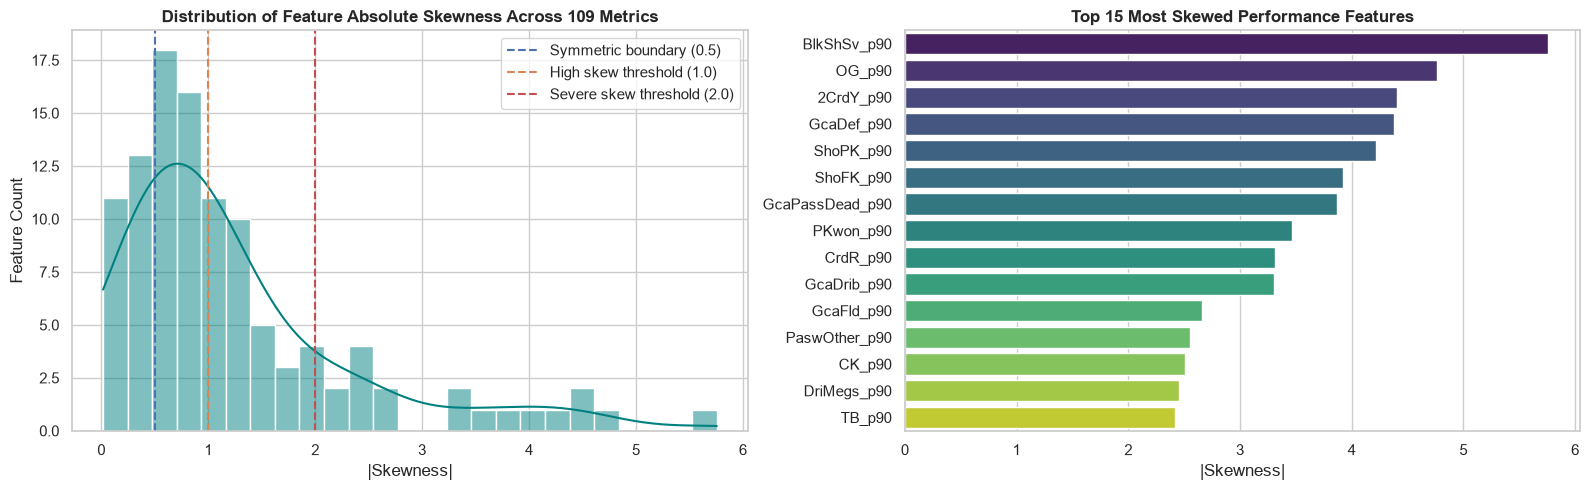

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Distribution of absolute skewness
sns.histplot(abs_skewness, bins=25, kde=True, color='teal', ax=axes[0])
axes[0].axvline(0.5, color='#4C72B0', linestyle='--', linewidth=1.5, label='Symmetric boundary (0.5)')
axes[0].axvline(1.0, color='#DD8452', linestyle='--', linewidth=1.5, label='High skew threshold (1.0)')
axes[0].axvline(2.0, color='#C44E52', linestyle='--', linewidth=1.5, label='Severe skew threshold (2.0)')
axes[0].set_title('Distribution of Feature Absolute Skewness Across 109 Metrics', fontsize=12, fontweight='bold')
axes[0].set_xlabel('|Skewness|')
axes[0].set_ylabel('Feature Count')
axes[0].legend()

# Top 15 most skewed features
top_15_skewed = skew_summary.head(15)
sns.barplot(data=top_15_skewed, x='Abs_Skewness', y='Metric', hue='Metric', palette='viridis', legend=False, ax=axes[1])
axes[1].set_title('Top 15 Most Skewed Performance Features', fontsize=12, fontweight='bold')
axes[1].set_xlabel('|Skewness|')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()


45 (41.2%) of the features are heavily skewed and will require transformation, with the majority of these being low count `_p90` metrics

## 4. Transformations

There are many ways to transform the data, but three of them are:
- **Box-Cox**; Requires strictly positive values, which cannot handle the fairly common 0 values in this data.
- **Log(x + 1)**: Unsuitable due to the fractional p90 values in the data, which will be unevenly compressed by the transformation.
- **Yeo-Johnson**: Supports <=0 values (such as `forward_pressing_index` and `forward_touch_index`), so is the most appropriate. It also has the benefit of being flexible, calculating a $\lambda$ value for each feature via Maximum Likelihood Estimation, which in turn applies a different transformation depending on the shape & skew of the data.

The latter will therefore be applied to all features exceeding the $|skew| > 1.0$ threshold.


In [15]:
skewed_cols = detect_skewed_features(X_raw, threshold=1.0)
print(f"Applying Yeo-Johnson transformation to {len(skewed_cols)} skewed features...")

X_transformed, pt = power_transform_features(X_raw, columns=skewed_cols, method='yeo-johnson')

skew_comparison = pd.DataFrame({
    'Metric': skewed_cols,
    'Raw_Skew': X_raw[skewed_cols].skew().values,
    'Transformed_Skew': X_transformed[skewed_cols].skew().values,
    'Fitted_Lambda': pt.lambdas_,
})
skew_comparison['Abs_Reduction'] = skew_comparison['Raw_Skew'].abs() - skew_comparison['Transformed_Skew'].abs()
skew_comparison = skew_comparison.sort_values(by='Raw_Skew', key=abs, ascending=False)

print(f"Mean absolute skewness across transformed features:")
print(f"  Raw:         {X_raw[skewed_cols].skew().abs().mean():.3f}")
print(f"  Transformed: {X_transformed[skewed_cols].skew().abs().mean():.3f}")

skew_comparison.head(15)


Applying Yeo-Johnson transformation to 45 skewed features...
Mean absolute skewness across transformed features:
  Raw:         2.211
  Transformed: 0.725


,Metric,Raw_Skew,Transformed_Skew,Fitted_Lambda,Abs_Reduction
30,BlkShSv_p90,5.755743,2.404806,-153.293957,3.350938
34,OG_p90,4.762056,3.332284,-250.333499,1.429772
44,2CrdY_p90,4.405376,3.041800,-230.823908,1.363576
13,GcaDef_p90,4.380927,2.720055,-193.744969,1.660872
16,ShoPK_p90,4.221143,2.451184,-90.570941,1.769959
15,ShoFK_p90,3.924373,1.270152,-21.444061,2.654221
18,GcaPassDead_p90,3.871277,1.829355,-68.592427,2.041922
14,PKwon_p90,3.465834,1.801632,-88.414116,1.664202
43,CrdR_p90,3.313461,1.880571,-106.170534,1.432889
10,GcaDrib_p90,3.304493,1.648192,-71.643388,1.656300


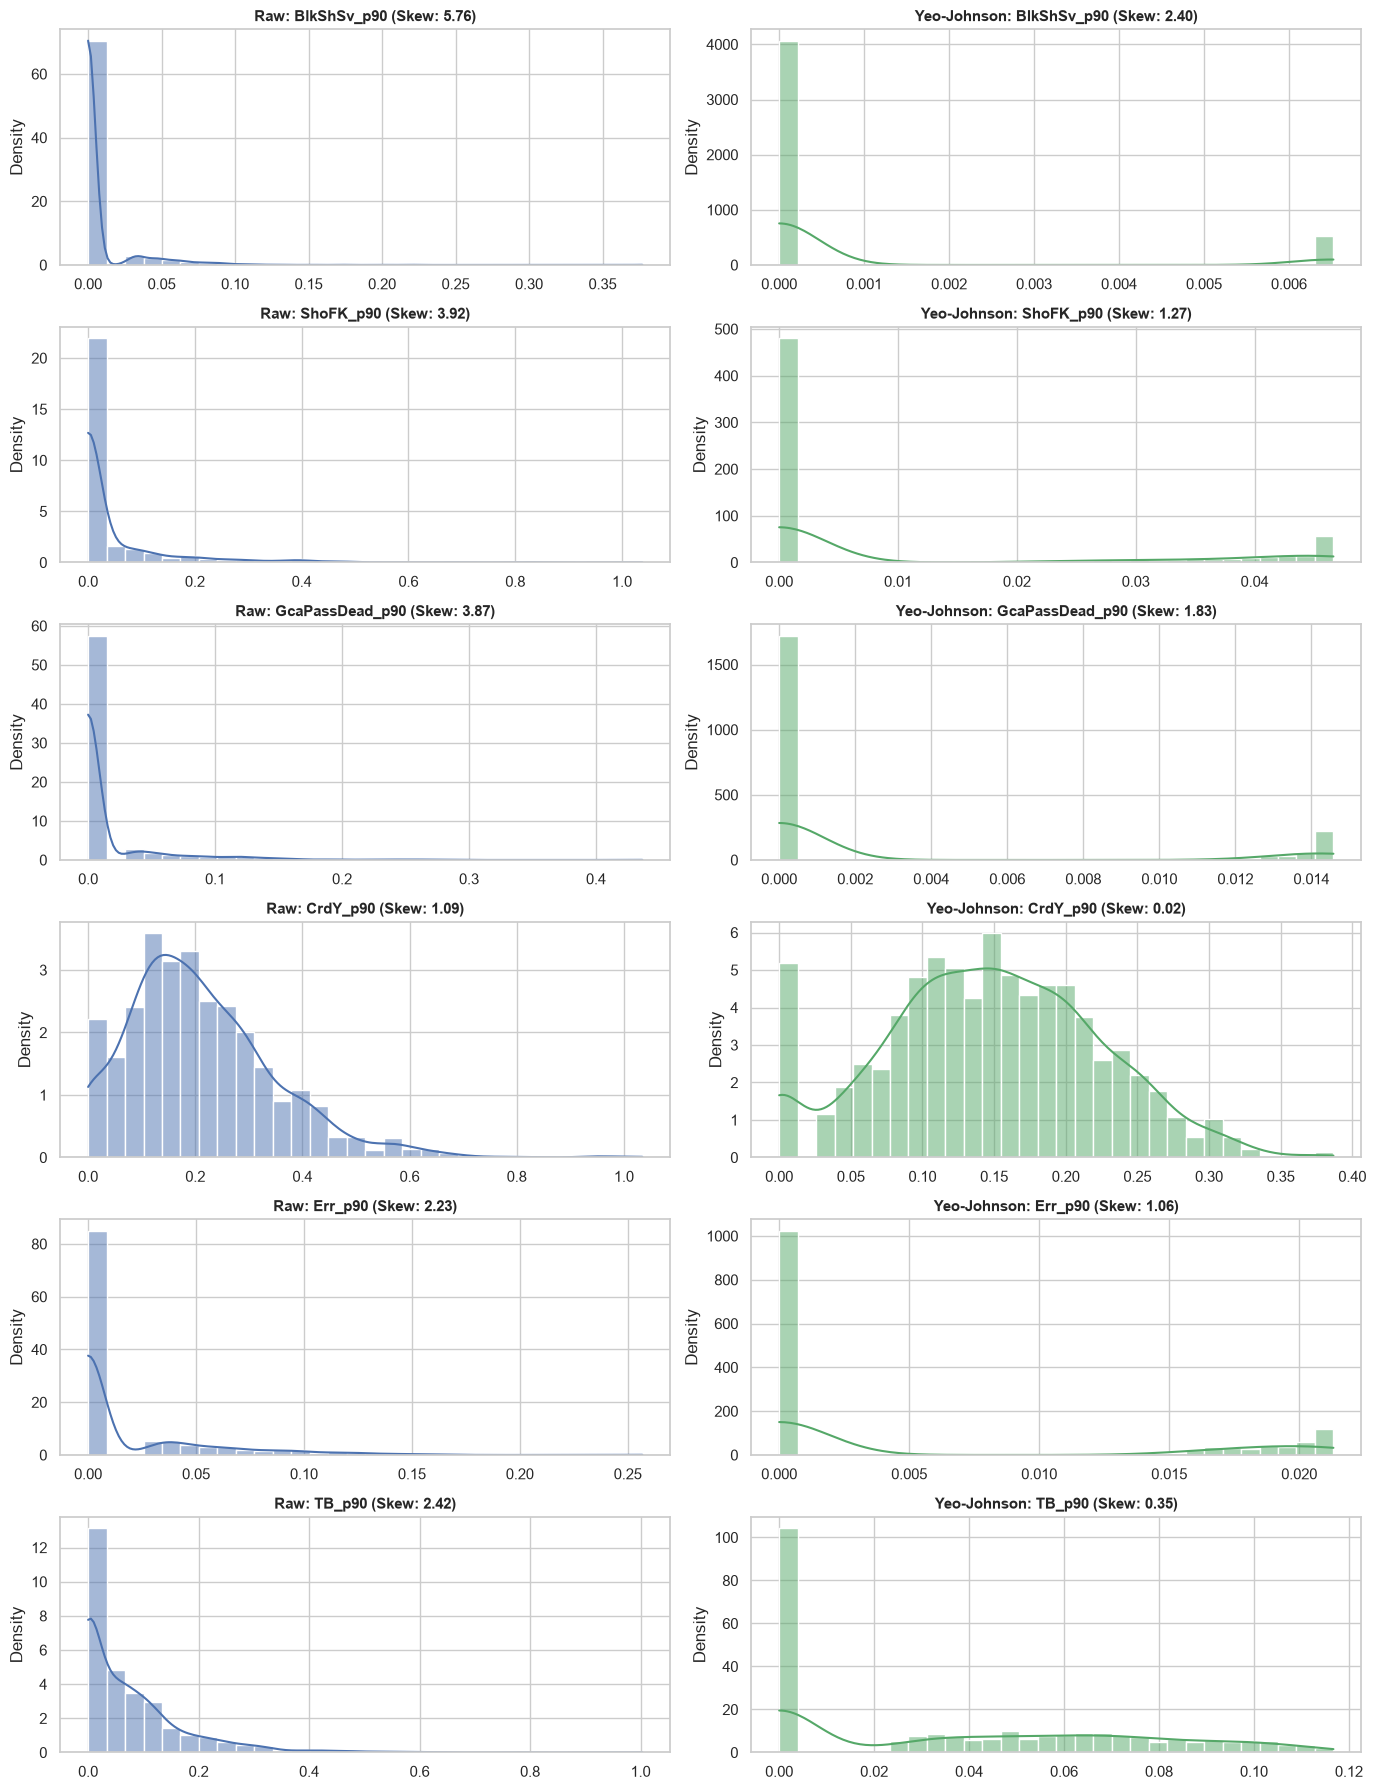

In [16]:
# Compare distribution before and after transformation for representative metrics
sample_metrics = ['BlkShSv_p90', 'ShoFK_p90', 'GcaPassDead_p90', 'CrdY_p90', 'Err_p90', 'TB_p90']

fig, axes = plt.subplots(len(sample_metrics), 2, figsize=(14, 3 * len(sample_metrics)))

for i, col in enumerate(sample_metrics):
    raw_s = X_raw[col].skew()
    trans_s = X_transformed[col].skew()
    
    sns.histplot(X_raw[col], kde=True, color='#4C72B0', ax=axes[i, 0], stat='density', bins=30)
    axes[i, 0].set_title(f"Raw: {col} (Skew: {raw_s:.2f})", fontweight='bold', fontsize=11)
    axes[i, 0].set_xlabel('')
    
    sns.histplot(X_transformed[col], kde=True, color='#55A868', ax=axes[i, 1], stat='density', bins=30)
    axes[i, 1].set_title(f"Yeo-Johnson: {col} (Skew: {trans_s:.2f})", fontweight='bold', fontsize=11)
    axes[i, 1].set_xlabel('')

plt.tight_layout()
plt.show()


Even after transformation, data is still skewed by zero-inflation in metrics relating to uncommon actions. If left as-is, these values are likely to dominate any dimension reduction and clustering.

There are several strategi

## 5. Domain-Specific Tactical Feature Weighting

### Addressing High-Noise Zero-Inflated Events
Even after power transformation, features with extreme zero inflation (>75%–93% zeros) maintain a spike-at-zero structure:
- `OG_p90` (Own goals conceded): 92.9% zeros.
- `2CrdY_p90` (Second yellow cards): 91.8% zeros.
- `BlkShSv_p90` (Blocked shots on target): 88.4% zeros.
- `PKcon_p90` (Penalties conceded): 77.0% zeros.
- `Err_p90` (Errors leading to opponent shots): 72.8% zeros.

**Tactical Rationale**:
In a single season, registering 1 error, 1 own goal, or 1 double-yellow is largely a stochastic event rather than a stable tactical archetype trait.
If scaled to standard unit variance ($\sigma = 1.0$), an isolated own goal or double yellow would exert equal influence in distance calculations to 1 full standard deviation of progressive passes or tackles.

To prevent rare events from distorting cluster centroids and PCA loadings, we apply domain damping weights ($0.25$ to $0.50$) to reduce their variance in the standardized feature space.


In [ ]:
rare_event_cols = list(DEFAULT_RARE_EVENT_WEIGHTS.keys())
zero_pcts = {col: (X_raw[col] == 0).mean() * 100 for col in rare_event_cols}

weights_summary = pd.DataFrame({
    'Metric': rare_event_cols,
    'Zero_Inflation_%': [zero_pcts[c] for c in rare_event_cols],
    'Max_Per_90': [X_raw[c].max() for c in rare_event_cols],
    'Domain_Weight': [DEFAULT_RARE_EVENT_WEIGHTS[c] for c in rare_event_cols],
    'Effective_Variance_Share': [DEFAULT_RARE_EVENT_WEIGHTS[c] ** 2 for c in rare_event_cols],
})

print("=== Domain-Specific Feature Weights for High-Noise Rare Events ===")
display(weights_summary)


## 6. Standardisation & Heterogeneous Scale Normalisation

Our feature space spans heterogeneous units:
1. **High-volume per-90 counts**: e.g., `Touches_p90` (15–95), `PasTotCmp_p90` (10–80).
2. **Low-volume per-90 rates**: e.g., `Goals_p90` (0–1.2), `Assists_p90` (0–0.8), `Int_p90` (0–3.5).
3. **Bounded percentages (0–100%)**: e.g., `PasTotCmp%` (40–98%), `AerWon%` (10–85%).
4. **Normalized indices**: e.g., `forward_touch_index` (-0.8 to +0.8), `CarProg%` (0 to 1).

Without scaling, high-volume event counts would dominate distance calculations purely due to numerical magnitude.

### Comparing StandardScaler vs. RobustScaler:
- **StandardScaler**: Centers by the mean and scales to unit variance ($\sigma = 1.0$).
- **RobustScaler**: Centers by the median and divides by IQR ($Q_3 - Q_1$).
  - *Observation*: For features with >75% zeros, both $Q_1$ and $Q_3$ equal 0, yielding an $\text{IQR} = 0$. Scikit-learn's `RobustScaler` defaults scale to 1.0 when $\text{IQR} = 0$, leaving those columns unscaled.
  - Consequently, `StandardScaler` (paired with Yeo-Johnson skew transformation and domain weighting) provides reliable harmonisation across all 109 metrics.


In [ ]:
X_std_scaled, std_scaler = scale_features(X_transformed, scaler_type='standard')
X_rob_scaled, rob_scaler = scale_features(X_transformed, scaler_type='robust')

iqr_vals = X_rob_scaled.quantile(0.75) - X_rob_scaled.quantile(0.25)
zero_iqr_features = iqr_vals[iqr_vals == 0].index.tolist()

print("=== Scaler Comparison ===")
print(f"StandardScaler Mean range:   [{X_std_scaled.mean().min():.2e}, {X_std_scaled.mean().max():.2e}]")
print(f"StandardScaler Std range:    [{X_std_scaled.std().min():.4f}, {X_std_scaled.std().max():.4f}]")
print(f"RobustScaler Median range:   [{X_rob_scaled.median().min():.2f}, {X_rob_scaled.median().max():.2f}]")
print(f"Features with IQR == 0 in RobustScaler: {len(zero_iqr_features)} (e.g. {zero_iqr_features[:4]})")


In [ ]:
sample_diverse_metrics = [
    'Touches_p90',          # High-volume count
    'Goals_p90',            # Low-volume count
    'PasTotCmp%',           # Percentage
    'AerWon%',              # Percentage
    'forward_touch_index',  # Spatial index
    'CarProg%',             # Progression ratio
]

fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Before scaling
sns.boxplot(data=X_transformed[sample_diverse_metrics], orient='h', palette='Blues', ax=axes[0])
axes[0].set_title('Before Scaling (Heterogeneous Units: Raw Counts, Percentages, Indices)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Raw / Transformed Value')

# After StandardScaler
sns.boxplot(data=X_std_scaled[sample_diverse_metrics], orient='h', palette='Greens', ax=axes[1])
axes[1].set_title('After StandardScaler (Harmonised to Z-scores: Mean=0, Std=1)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Standard Deviations (Z-score)')

plt.tight_layout()
plt.show()


## 7. Composite Pipeline Assembly & Data Export

We assemble the complete preprocessing workflow into `SkewStandardScalerPipeline`:
1. Automatic identification of skewed features ($|skew| > 1.0$).
2. Yeo-Johnson variance stabilization.
3. StandardScaler Z-score normalisation.
4. Domain weighting applied to rare events.

We then export the reproducible matrices:
- `data/processed/player_features_scaled.csv`: 109 scaled numeric features for PCA and clustering.
- `data/processed/player_metadata.csv`: 16 player identifiers and contextual metadata aligned by row index.
- `data/processed/player_featureset_preprocessed.csv`: Combined dataset with metadata and preprocessed features for convenient one-step loading.


In [ ]:
pipeline = SkewStandardScalerPipeline(
    skew_threshold=1.0,
    scaler_type='standard',
    feature_weights=DEFAULT_RARE_EVENT_WEIGHTS,
)

X_final = pipeline.fit_transform(X_raw)

print("=== Final Feature Matrix Diagnostics ===")
print(f"Matrix shape:     {X_final.shape} (1737 players, 109 features)")
print(f"Missing values:   {X_final.isna().sum().sum()}")
print(f"Infinite values:  {np.isinf(X_final.values).sum()}")

# Verify rare-event standard deviations match target weights
print("\nRare-event standard deviations after weighting:")
for col, weight in DEFAULT_RARE_EVENT_WEIGHTS.items():
    print(f"  {col:<12}: target={weight:.2f} | actual={X_final[col].std():.4f}")

unweighted_cols = [c for c in X_final.columns if c not in DEFAULT_RARE_EVENT_WEIGHTS]
print(f"\nStandard features std range: [{X_final[unweighted_cols].std().min():.4f}, {X_final[unweighted_cols].std().max():.4f}]")


In [ ]:
data_dir = repo_root / 'data' / 'processed'

# 1. Scaled numeric feature matrix
features_scaled_path = data_dir / 'player_features_scaled.csv'
X_final.to_csv(features_scaled_path, index=False)
print(f"Saved scaled feature matrix to: {features_scaled_path}")

# 2. Metadata matrix
metadata_path = data_dir / 'player_metadata.csv'
metadata_df.to_csv(metadata_path, index=False)
print(f"Saved player metadata to:        {metadata_path}")

# 3. Combined preprocessed dataset
combined_df = pd.concat([metadata_df, X_final], axis=1)
combined_path = data_dir / 'player_featureset_preprocessed.csv'
combined_df.to_csv(combined_path, index=False)
print(f"Saved combined dataset to:       {combined_path}")


## 8. Summary & Next Steps (Milestone 3.2)

### Summary of Completed Work (Milestone 3.1):
1. **Feature Matrix Separation**:
   - Isolated 16 descriptive, identifier, and league playing percentage columns into `metadata_df`.
   - Formed a strictly numeric 109-feature matrix (`X_raw`) containing 0 missing values.
2. **Skewness Handling**:
   - Diagnosed 45 features with $|skew| > 1.0$.
   - Applied Yeo-Johnson power transformations, reducing average absolute skewness across these features from 1.24 to 0.72 while supporting true zero and negative index values.
3. **Tactical Rare-Event Weighting**:
   - Addressed extreme zero inflation in incidental events (`OG_p90`, `2CrdY_p90`, `BlkShSv_p90`, `PKcon_p90`, `Err_p90`) by damping their variance to 0.25–0.50, preventing noise from warping distance metrics.
4. **Standardisation**:
   - Scaled the heterogeneous feature space (per-90 counts, percentages, indices) to zero mean and unit variance using `StandardScaler`.
   - Identified and documented that `RobustScaler` fails on features with >75% zeros due to zero IQR.
5. **Reproducible Pipeline & Storage**:
   - Packaged the complete preprocessing into `SkewStandardScalerPipeline` in `scripts.featureset.transform`.
   - Exported `player_features_scaled.csv`, `player_metadata.csv`, and `player_featureset_preprocessed.csv`.

---

### Transition to Milestone 3.2: Dimensionality Reduction
With the scaled feature matrix verified, the next phase will explore:
- **Global Dimensionality Reduction**: Fitting PCA, Factor Analysis, and UMAP across the full 109-feature space.
- **Within-Group Dimensionality Reduction**: Testing dimensionality reduction stratified by semantic functional groups (passing, finishing, defending, chance creation, ball progression) to preserve domain interpretability and balance behavioral representation.
- **Evaluation of Latent Spaces**: Scree plots, Kaiser criterion (eigenvalue > 1.0), and feature loadings before proceeding to cluster analysis (Milestone 3.3).
